# PCD Assignment 03
## Image Segmentation and Morphological Processing

**Name:** Nabila Aisy Shifa

**NIM:** 25/560484/PA/23619  

**Kelas:** KOMA

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [4]:
from google.colab import files

uploaded = files.upload()

Saving achilles.png to achilles.png


In [5]:
image = cv2.imread("achilles.png")

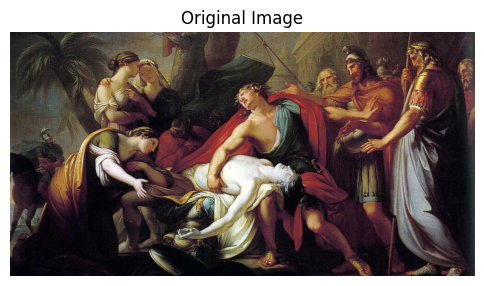

In [6]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Original Image")
plt.show()

Grayscale

Tahap grayscale digunakan untuk mengubah citra RGB menjadi citra grayscale. Citra grayscale hanya memiliki satu kanal intensitas, sehingga lebih sederhana untuk digunakan pada proses segmentasi berdasarkan nilai piksel.

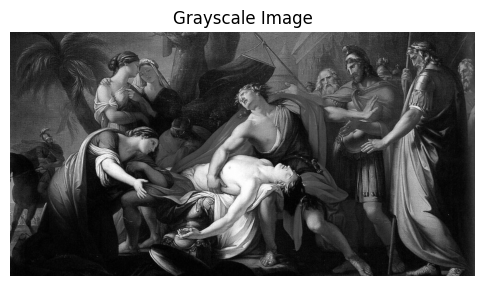

In [9]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(6, 6))
plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.title("Grayscale Image")
plt.show()

Segmentasi dengan Thresholding

Segmentasi digunakan untuk memisahkan objek dengan latar belakang berdasarkan nilai intensitas piksel. Pada proses ini digunakan nilai threshold sebesar 128. Piksel dengan intensitas lebih besar dari threshold akan menjadi putih, sedangkan piksel lainnya menjadi hitam.

In [10]:
threshold = 128

binary = np.zeros_like(gray)

for i in range(gray.shape[0]):
    for j in range(gray.shape[1]):
        if gray[i, j] > threshold:
            binary[i, j] = 255
        else:
            binary[i, j] = 0

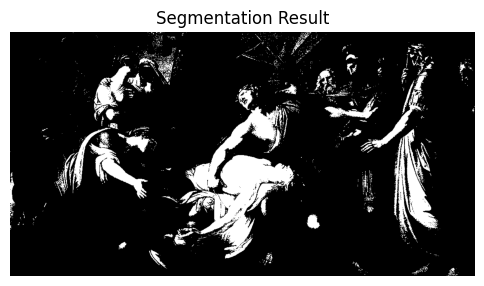

In [11]:
plt.figure(figsize=(6, 6))
plt.imshow(binary, cmap="gray")
plt.axis("off")
plt.title("Segmentation Result")
plt.show()

Structuring Element

Structuring element merupakan elemen berbentuk matriks kecil yang digunakan sebagai pola dalam operasi morfologi. Pada percobaan ini digunakan structuring element berbentuk persegi berukuran \(3 \times 3\), dengan seluruh elemennya bernilai 1. Elemen ini digunakan untuk memproses citra biner pada operasi dilation dan erosion.

In [12]:
kernel = np.ones((3, 3), dtype=np.uint8)

print("Structuring Element 3x3:")
print(kernel)

Structuring Element 3x3:
[[1 1 1]
 [1 1 1]
 [1 1 1]]


Dilation

Dilation merupakan operasi morfologi yang memperluas area foreground (piksel putih) pada citra biner. Dalam implementasi ini, setiap piksel diperiksa bersama tetangga di sekitarnya menggunakan structuring element \(3 \times 3\). Jika terdapat setidaknya satu piksel putih pada area tersebut, piksel hasil akan bernilai putih.

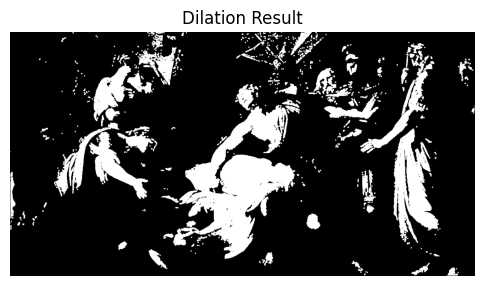

In [13]:
height, width = binary.shape
dilated = np.zeros_like(binary)

for i in range(1, height - 1):
    for j in range(1, width - 1):
        region = binary[i-1:i+2, j-1:j+2]

        if np.any(region == 255):
            dilated[i, j] = 255
        else:
            dilated[i, j] = 0

plt.figure(figsize=(6, 6))
plt.imshow(dilated, cmap="gray")
plt.axis("off")
plt.title("Dilation Result")
plt.show()

Erosion

Erosion merupakan operasi morfologi yang memperkecil area foreground pada citra biner. Piksel hasil hanya akan menjadi putih jika seluruh piksel pada area \(3 \times 3\) bernilai putih. Jika terdapat piksel hitam pada area tersebut, piksel hasil akan menjadi hitam.

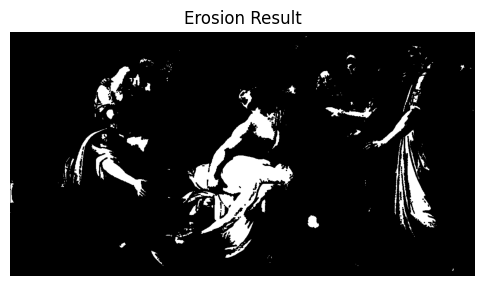

In [14]:
height, width = binary.shape
eroded = np.zeros_like(binary)

for i in range(1, height - 1):
    for j in range(1, width - 1):
        region = binary[i-1:i+2, j-1:j+2]

        if np.all(region == 255):
            eroded[i, j] = 255
        else:
            eroded[i, j] = 0

plt.figure(figsize=(6, 6))
plt.imshow(eroded, cmap="gray")
plt.axis("off")
plt.title("Erosion Result")
plt.show()

Opening

Opening merupakan operasi morfologi yang dilakukan dengan menerapkan erosion terlebih dahulu, kemudian dilation menggunakan structuring element yang sama. Operasi ini dapat membantu menghilangkan noise kecil pada foreground tanpa mengubah bentuk objek secara berlebihan.

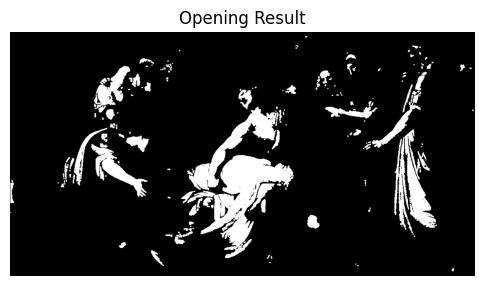

In [15]:
opened = np.zeros_like(eroded)
height, width = eroded.shape

for i in range(1, height - 1):
    for j in range(1, width - 1):
        region = eroded[i-1:i+2, j-1:j+2]

        if np.any(region == 255):
            opened[i, j] = 255

plt.figure(figsize=(6, 6))
plt.imshow(opened, cmap="gray")
plt.axis("off")
plt.title("Opening Result")
plt.show()

Closing

Closing merupakan operasi morfologi yang dilakukan dengan menerapkan dilation terlebih dahulu, kemudian erosion menggunakan structuring element yang sama. Operasi ini dapat membantu mengisi lubang kecil dan menghubungkan celah sempit pada foreground.

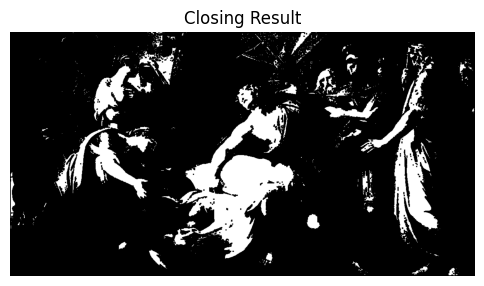

In [16]:
closing_dilation = np.zeros_like(binary)
height, width = binary.shape

for i in range(1, height - 1):
    for j in range(1, width - 1):
        region = binary[i-1:i+2, j-1:j+2]

        if np.any(region == 255):
            closing_dilation[i, j] = 255

closed = np.zeros_like(closing_dilation)

for i in range(1, height - 1):
    for j in range(1, width - 1):
        region = closing_dilation[i-1:i+2, j-1:j+2]

        if np.all(region == 255):
            closed[i, j] = 255

plt.figure(figsize=(6, 6))
plt.imshow(closed, cmap="gray")
plt.axis("off")
plt.title("Closing Result")
plt.show()

Perbandingan Hasil Segmentasi

Pada tahap ini, hasil segmentasi awal dibandingkan dengan hasil setelah penerapan operasi morfologi. Perbandingan dilakukan untuk mengamati perubahan bentuk foreground, pengurangan noise, serta kemungkinan pengisian lubang atau celah kecil.

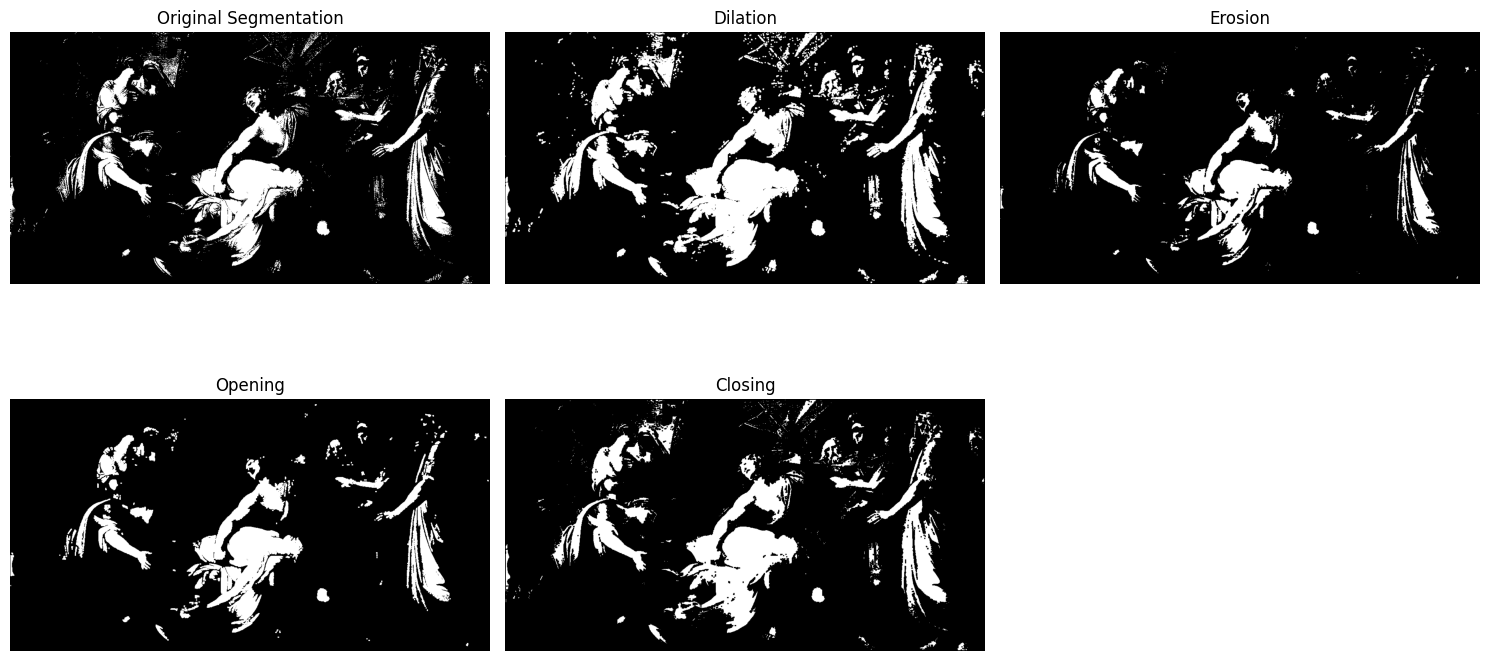

In [17]:
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(binary, cmap="gray")
plt.title("Original Segmentation")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(dilated, cmap="gray")
plt.title("Dilation")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(eroded, cmap="gray")
plt.title("Erosion")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(opened, cmap="gray")
plt.title("Opening")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(closed, cmap="gray")
plt.title("Closing")
plt.axis("off")

plt.tight_layout()
plt.show()